In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis as mda
import MDAnalysis
from typing import Dict, Tuple
import os
import seaborn as sns

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

outpath = './S2_analyses_nonblockHDXrew/'


In [11]:
# here we take the optimal weights from HDX reweighting and simply sum the weights in blocks used for calculating the order parameters
# within the blocks we calculate average S2 as if unbiased to preserve dynamics of the original trajectory

proteins = ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

time_factors = [0.5, 1, 2, 3, 5, 10]
for time_factor in time_factors:
    print(f"Time factor: {time_factor}")

    for protein in proteins:
        print(protein)
        
        traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

        n_models = len(models)
        ncols=4
        fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))


        # experimental data
        try:
            exp_res, exp_S2 = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/S2_NH.dat', unpack=True)
        except:
            exp_res, exp_S2, exp_S2_err = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/S2_NH.dat', unpack=True)
        MD_scaling = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/alpha_S2_MD.dat')
        info = pd.read_csv(f"../../ORTHOGONAL_EXP_DATA/{protein}/info.csv")
        TAUR = float(info[info['Experiment']=='S2_NH']['S2_iso_tauc'])
        window_ns = TAUR * time_factor
        frame_dt_ps = 100.0

        # convert ns -> frames (frame_dt is in ps)
        n_frames = int(np.load(f"../../MD_DATA/{protein}/{models[0]}/wopt.npy").shape[0])
        frames_per_window = max(1, int(round(window_ns * 1000.0 / float(frame_dt_ps))))
        starts = list(range(0, n_frames - frames_per_window + 1, frames_per_window))

        for i, model in enumerate(models):
            print(model)
            exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
            if model in ('rewBV2006', 'rewBV2006ang'):
                wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
            else:
                wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
                wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

            blocksum_wopt = []
            for iw, ws in enumerate(starts):
                we = ws + frames_per_window  # exclusive
                block = wopt[ws:we]   # shape (fw, n_bonds, 3)
                blocksum_wopt.append(np.sum(block))
            blocksum_wopt = np.array(blocksum_wopt)

            blocksum_wopt_array = []
            for W in wopt_array:
                curr = []
                for iw, ws in enumerate(starts):
                    we = ws + frames_per_window  # exclusive
                    block = W[ws:we]   # shape (fw, n_bonds, 3)
                    curr.append(np.sum(block))
                curr = np.array(curr)
                blocksum_wopt_array.append(curr)
            blocksum_wopt_array = np.array(blocksum_wopt_array)

            savedf = pd.DataFrame()
            savedf['Neff'] = phi

            # load calculated S2 data
            calcS2 = np.load(f"../../MD_DATA/{protein}/S2blocks/S2_blocks_{time_factor}xTAUR.npy") * MD_scaling
            # S2 calculated residues
            S2resids = np.loadtxt(f"../../MD_DATA/{protein}/S2blocks/S2_residues.txt").astype(int)
            # get indices for which experimental S2 exist
            S2idxs = np.array([list(S2resids).index(ele) for ele in exp_res])

            expPF = np.array(exp["PF"][idxs])
            rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
            rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
            r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
            r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

            # calculate RMSE to validation data: only NOE distances that are below lower bound or above upper bound (RMSE=0 for distances that are within the range)
            validation_diff = []
            for W in blocksum_wopt_array:
                S2w = np.average(calcS2, axis=0, weights=W)
                rmse = RMSE(exp_S2, S2w[S2idxs])
                validation_diff.append(rmse)

            savedf['S2_RMSE'] = validation_diff

            prior_avg = np.average(calcS2, axis=0)
            post_avg = np.average(calcS2, axis=0, weights=blocksum_wopt)
            S2_rmse_prior = RMSE(exp_S2, prior_avg[S2idxs])
            S2_rmse_post = RMSE(exp_S2, post_avg[S2idxs])

            # --- Plot 1: neff vs RMSE with validation data ---
            ax = axes[i, 0]
            ax.scatter(phi, validation_diff, c="tab:red")
            ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("RMSE")
            ax.set_title(f"{model}")
            ax.set_ylim(0, np.max(np.abs(validation_diff))*1.2 )

            # --- Plot 2: Per-residue PFs ---
            ax = axes[i, 1]
            ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
            ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
            ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
            ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
            ax.set_yscale("log")
            ax.set_ylim(0,1e8)
            ax.set_xlabel("Residue"); ax.set_ylabel("PF")

            # --- Plot 3: PF exp vs calc prior and posterior ---
            ax = axes[i, 2]
            ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
            ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
            ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
            ax.plot([-10, 1e10], [-10, 1e10], color='black', linestyle='dashed', linewidth=1)
            ax.set_yscale("log")
            ax.set_xscale("log")
            ax.set_ylim(0,1e8)
            ax.set_xlim(0,1e8)
            ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

            # --- Plot 4: S2 data ---

            ax = axes[i, 3]

            # prior and posterior RMSE
            ax.set_title(f"Prior: RMSE={S2_rmse_prior:.2f}\nPosterior: RMSE={S2_rmse_post:.2f}")

            # experimental and ensemble averaged values
            ax.bar(exp_res, exp_S2, color="lightblue", alpha=0.5, label="Exp.")
            ax.scatter(S2resids, prior_avg, color="tab:blue", label="Prior", zorder=20)
            ax.scatter(S2resids, post_avg, color="tab:red", label="Posterior", zorder=20)

            ax.set_ylabel('S$^2$')
            ax.set_xlabel('Residue')

            ax.set_ylim(0,1)

            # set legend
            ax.legend(loc='lower right')

            # save validation diff data 
            savedf.to_csv(outpath+f"{protein}_{model}_S2_validation_{time_factor}xTAUR.csv")

            
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.savefig(outpath+f"{protein}_HDXrew_S2_NH_{time_factor}xTAUR.png", dpi=200, bbox_inches="tight")
        plt.close()
            


Time factor: 0.5
alpha3D


/tmp/ipykernel_1769435/1201988216.py:29: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  TAUR = float(info[info['Experiment']=='S2_NH']['S2_iso_tauc'])


rewBV2006


/tmp/ipykernel_1769435/1201988216.py:110: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:121: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:122: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1e8)


rewBV2006ang


...

/tmp/ipykernel_1769435/1201988216.py:110: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:121: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:122: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1e8)


rewM14DH


/tmp/ipykernel_1769435/1201988216.py:110: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:121: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:122: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1e8)


rewM14DH_scaled


/tmp/ipykernel_1769435/1201988216.py:110: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:121: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,1e8)
/tmp/ipykernel_1769435/1201988216.py:122: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,1e8)


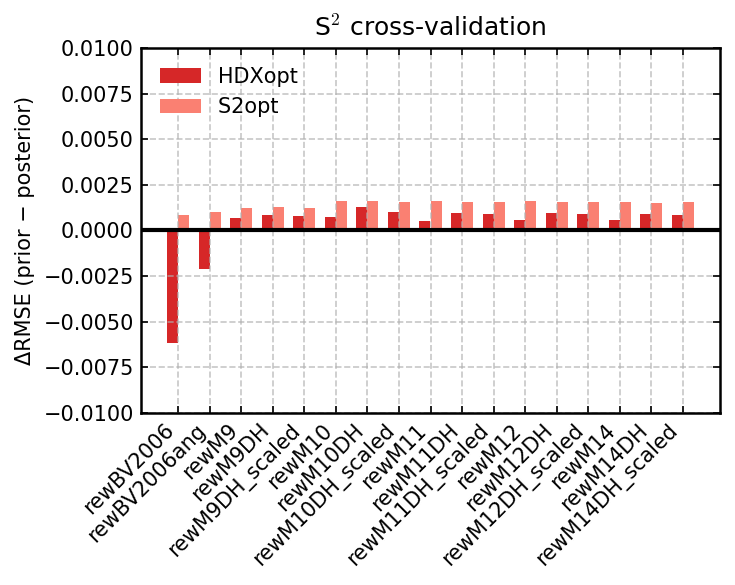

In [17]:
proteins = ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

time_factor = 1

# summary barplot (delta S2 RMSE prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (S2opt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_S2_validation_{time_factor}xTAUR.csv')

        prior.append(list(dat['S2_RMSE'])[0])
        post1.append(list(dat['S2_RMSE'])[-1])
        post2.append(np.min(dat['S2_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['S2opt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['S2opt'], width, label='S2opt ', color = 'salmon')

ax.set_ylabel('ΔRMSE (prior − posterior)')
ax.set_title('S$^2$ cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.01,0.01)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'S2_validation_summary_{time_factor}xTAUR.png',dpi=300)






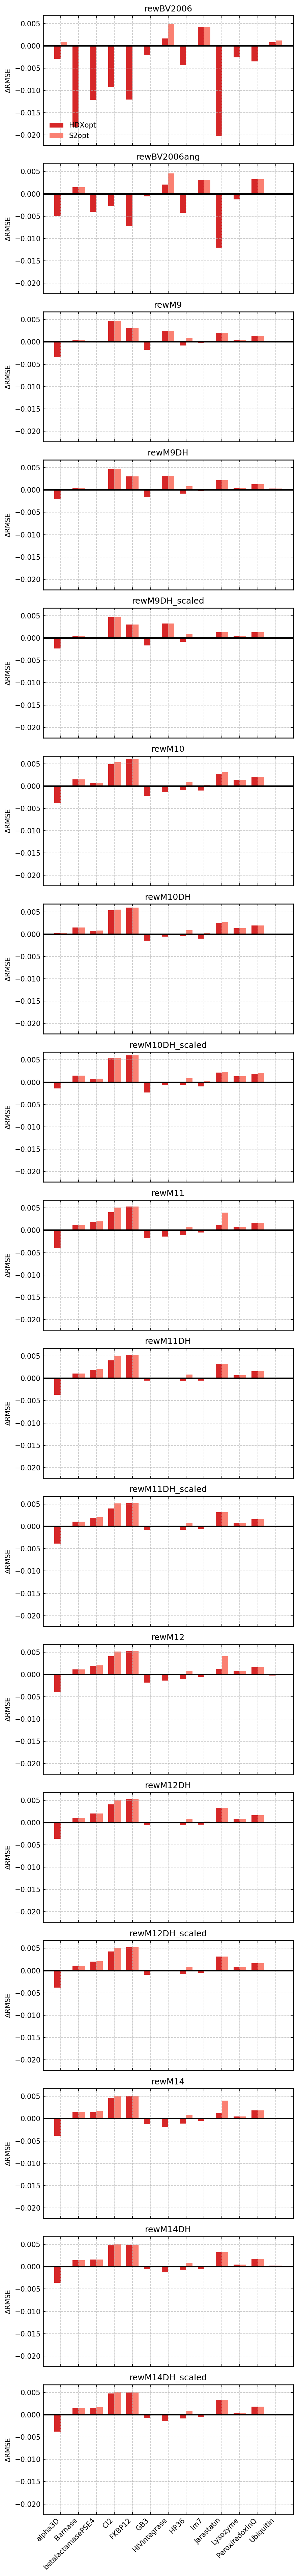

In [23]:
proteins = ['alpha3D', 'Barnase', 'betalactamasePSE4', 'CI2', 'FKBP12', 'GB3', 'HIVintegrase', 'HP36', 'Im7', 'Jarastatin', 'Lysozyme', 'PeroxiredoxinQ', 'Ubiquitin']
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

time_factor = 1

# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_S2_validation_{time_factor}xTAUR.csv')

        prior = list(dat['S2_RMSE'])[0]
        post1 = list(dat['S2_RMSE'])[-1]
        post2 = np.min(dat['S2_RMSE'])

        delta_HDXopt = prior - post1
        delta_S2opt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "S2opt": delta_S2opt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(6, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "S2opt"]].min().min() * 1.1
ymax = df[["HDXopt", "S2opt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["S2opt"], width, label="S2opt", color="salmon")

    ax.axhline(0, color="black")
    ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔRMSE")

    if idx == 0:
        ax.legend(loc="lower left")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + f"S2_validation_per_protein_per_model_{time_factor}xTAUR.png", dpi=300)

